# Univariate Analyis: Temperature Data

## Data Setup

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

#our data files use ";" between columns and "," as a decimal sign; and dep is a code (e.g "01")
read = dict(sep=";", decimal=",", dtype={"dep": str}, encoding = "utf-8-sig", parse_dates = ["date"])
deaths = pd.read_csv("data/DECES_2000_2025.csv", **read)
temp = pd.read_csv("data/TEMPERATURE_2000_2025.csv", **read)

age_sex = age_sex = [c for c in deaths.columns if c.startswith("deces_") and c != "deces_total"]
plt.rcParams["figure.figsize"] = (9, 3.5)

## Overview Data file

In [27]:
print("TEMPERATURE:", temp.shape[0], "rows,", temp.shape[1], "columns")
print(temp.dtypes.to_string())

TEMPERATURE: 902215 rows, 9 columns
date           datetime64[us]
region                    str
dep                       str
departement               str
tmin                  float64
tmax                  float64
tmean                 float64
rr                    float64
n_stations              int64


## Boxplot Temperature every 5 years (for Summer Months: June 1st unitl September 15th) 

In [29]:
import plotly.express as px

# extra columns in temp
temp["year"] = temp["date"].dt.year
temp["is_summer"] = temp["date"].dt.strftime("%m-%d").between("06-01", "09-15")   # 1 June – 15 September

# whole of France: average over the 95 départements for each day
france = temp.groupby("date")[["tmin", "tmax", "tmean"]].mean().reset_index()
france["year"] = france["date"].dt.year
france["is_summer"] = france["date"].dt.strftime("%m-%d").between("06-01", "09-15")

In [30]:
import json, urllib.request

# extra columns
temp["year"] = temp["date"].dt.year
temp["is_summer"] = temp["date"].dt.strftime("%m-%d").between("06-01", "09-15")   # 1 June – 15 September

# whole of France: average over the 95 départements for each day
france = temp.groupby("date")[["tmin", "tmax", "tmean"]].mean().reset_index()
france["year"] = france["date"].dt.year
france["is_summer"] = france["date"].dt.strftime("%m-%d").between("06-01", "09-15")

# 5-year periods (the last one has 6 years: 2020–2025)
france["period"] = pd.cut(france["year"], bins=[1999, 2004, 2009, 2014, 2019, 2025],
                          labels=["2000–2004", "2005–2009", "2010–2014", "2015–2019", "2020–2025"])

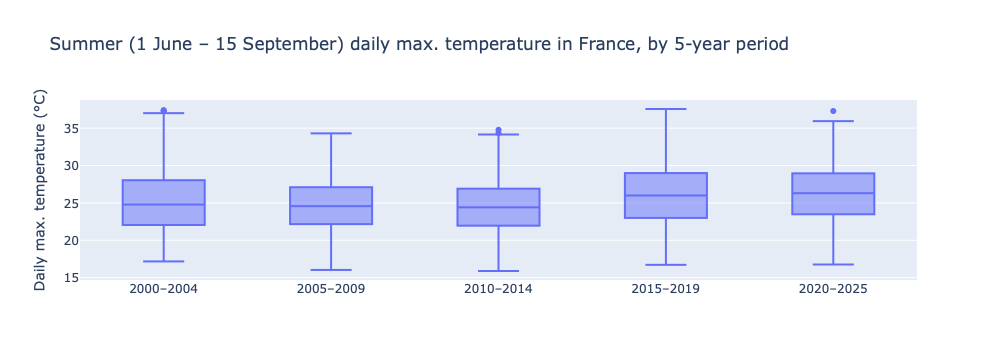

In [28]:
summer = france[france["is_summer"]]

fig_box = px.box(summer,
                 x="period",                              # one box per 5-year period
                 y="tmax",                                # daily max. temperature
                 points="outliers",                       # show only extreme days as dots
                 labels={"period": "", "tmax": "Daily max. temperature (°C)"},
                 title="Summer (1 June – 15 September) daily max. temperature in France, by 5-year period")
fig_box.show()

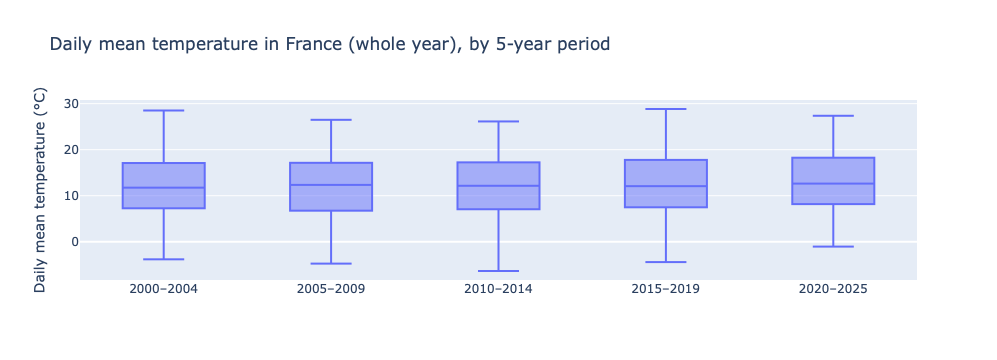

In [31]:
fig_box_year = px.box(france,
                      x="period",
                      y="tmean",                          # daily mean temperature
                      points="outliers",
                      labels={"period": "", "tmean": "Daily mean temperature (°C)"},
                      title="Daily mean temperature in France (whole year), by 5-year period")
fig_box_year.show()

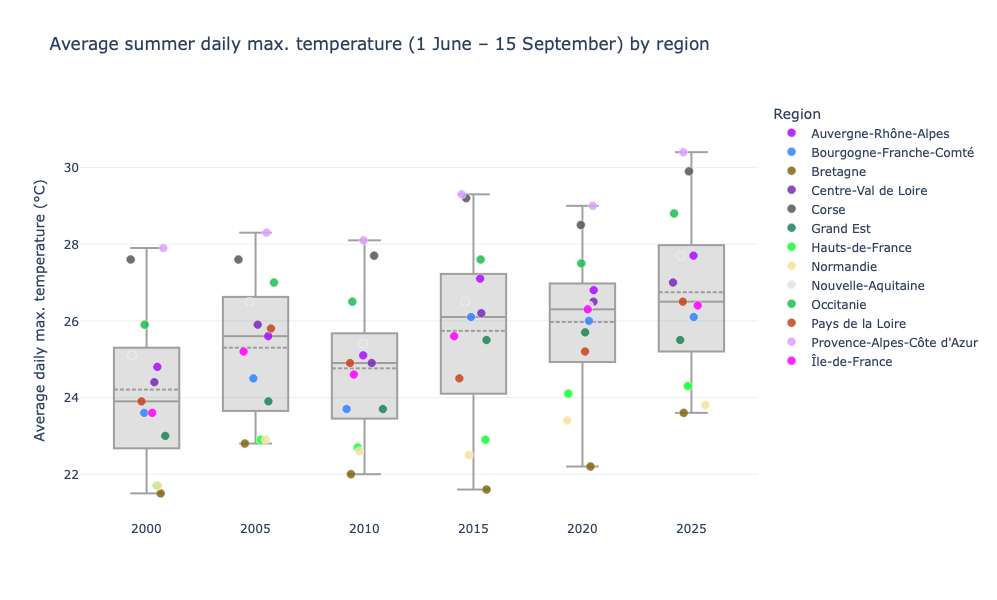

In [32]:
import numpy as np
import plotly.graph_objects as go

years = [2000, 2005, 2010, 2015, 2020, 2025]   # one year every five years
unit = "region"                                # "region" (13 points per year) or "departement" (95 points)

# 1. One value per unit and year: average daily max. temperature in summer (1 June – 15 September)
cols = ["region"] if unit == "region" else ["region", "departement"]
df_box = (temp[temp["is_summer"] & temp["year"].isin(years)]
          .groupby(["year", *cols])["tmax"].mean().round(1).reset_index())
df_box["name"] = df_box[unit]

# x position of each year (0, 1, 2, ...) plus a small random shift so the points don't overlap
pos = {y: i for i, y in enumerate(years)}
rng = np.random.default_rng(42)                               # fixed seed: same positions every run
df_box["x"] = df_box["year"].map(pos) + rng.uniform(-0.18, 0.18, len(df_box))

# 2. Grey box plot per year
fig = go.Figure()
for y in years:
    values = df_box.loc[df_box["year"] == y, "tmax"]
    fig.add_trace(go.Box(x=[pos[y]] * len(values), y=values,
                         boxmean=True,                       # dashed line = mean
                         boxpoints=False, width=0.6,
                         fillcolor="rgba(100, 100, 100, 0.20)",
                         line_color="rgba(150, 150, 150, 0.9)",
                         hoverinfo="skip", showlegend=False))

# 3. One coloured, hoverable point per region (or département), coloured by region
colors = px.colors.qualitative.Alphabet
region_colors = {r: colors[i % len(colors)] for i, r in enumerate(sorted(df_box["region"].unique()))}

for region, d in df_box.groupby("region"):
    fig.add_trace(go.Scatter(x=d["x"], y=d["tmax"], mode="markers", name=region,
                             marker=dict(color=region_colors[region], size=9, opacity=0.85,
                                         line=dict(width=0.5, color="white")),
                             customdata=d[["name", "year"]].to_numpy(),
                             hovertemplate="<b>%{customdata[0]}</b><br>Year: %{customdata[1]}<br>"
                                           "Avg. summer max. temp.: %{y:.1f} °C<extra></extra>"))

# 4. Invisible marker above each box: hover there to see the summary statistics
stats = (df_box.groupby("year")["tmax"]
         .agg(Minimum="min", Q1=lambda x: x.quantile(0.25), Median="median", Mean="mean",
              Q3=lambda x: x.quantile(0.75), Maximum="max")
         .reset_index())
stats["x"] = stats["year"].map(pos)
stats["hover_y"] = stats["Maximum"] + 0.04 * (df_box["tmax"].max() - df_box["tmax"].min())

fig.add_trace(go.Scatter(x=stats["x"], y=stats["hover_y"], mode="markers",
                         marker=dict(size=28, color="rgba(0,0,0,0)"),
                         customdata=stats[["Minimum", "Q1", "Median", "Mean", "Q3", "Maximum"]].to_numpy(),
                         text=stats["year"],
                         hovertemplate=("<b>Summer %{text}</b><br><br>"
                                        "Maximum: %{customdata[5]:.1f} °C<br>"
                                        "Q3: %{customdata[4]:.1f} °C<br>"
                                        "Mean: %{customdata[3]:.1f} °C<br>"
                                        "Median: %{customdata[2]:.1f} °C<br>"
                                        "Q1: %{customdata[1]:.1f} °C<br>"
                                        "Minimum: %{customdata[0]:.1f} °C<extra></extra>"),
                         showlegend=False))

# 5. Layout
fig.update_layout(
    title="Average summer daily max. temperature (1 June – 15 September) by region",
    xaxis=dict(title="", tickvals=list(pos.values()), ticktext=[str(y) for y in years]),
    yaxis=dict(title="Average daily max. temperature (°C)"),
    legend_title_text="Region",
    hovermode="closest",
    template="plotly_white",
    height=600)
fig.show()

## Distribution of Summer daily max. temp. comparing 2000-2012 and 2013-2025

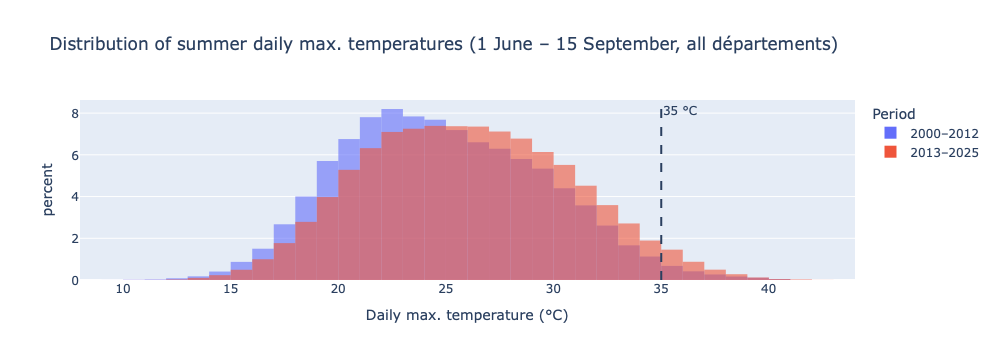

In [33]:
summer_dep = temp[temp["is_summer"]].copy()
summer_dep["half"] = "2000–2012"
summer_dep.loc[summer_dep["year"] >= 2013, "half"] = "2013–2025"

fig_hist = px.histogram(summer_dep,
                        x="tmax",
                        color="half",                     # one colour per period
                        barmode="overlay",                # both on top of each other
                        histnorm="percent",               # % of days, so both periods are comparable
                        nbins=60,
                        opacity=0.6,
                        labels={"tmax": "Daily max. temperature (°C)", "half": "Period"},
                        title="Distribution of summer daily max. temperatures (1 June – 15 September, all départements)")
fig_hist.add_vline(x=35, line_dash="dash", annotation_text="35 °C")   # mark very hot days
fig_hist.show()

## Heatmap for temperatures

In [ ]:
# outline of the 13 French regions (public GeoJSON file, needs internet)
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions.geojson"
regions_geo = json.load(urllib.request.urlopen(url))

# average daily max. temperature in summer, per region and year
summer_region = (temp[temp["is_summer"]]
                 .groupby(["region", "year"])["tmax"].mean().round(1).reset_index())

# position of each region name: approximate centre of the region's largest area
def centre(feature):
    geom = feature["geometry"]
    polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    ring = max((p[0] for p in polygons), key=len)          # outline of the largest part (e.g. mainland, not islands)
    a = cx = cy = 0
    for (x0, y0), (x1, y1) in zip(ring, ring[1:]):        # standard formula for the centre of a polygon
        cross = x0 * y1 - x1 * y0
        a += cross
        cx += (x0 + x1) * cross
        cy += (y0 + y1) * cross
    return cx / (3 * a), cy / (3 * a)

labels = pd.DataFrame([(f["properties"]["nom"], *centre(f)) for f in regions_geo["features"]],
                      columns=["region", "lon", "lat"])

fig_map = px.choropleth(summer_region,
                        geojson=regions_geo,
                        locations="region",                  # column with the region name
                        featureidkey="properties.nom",       # matching name in the GeoJSON file
                        color="tmax",
                        animation_frame="year",              # creates the slider
                        range_color=(summer_region["tmax"].min(), summer_region["tmax"].max()),  # same scale every year
                        color_continuous_scale="OrRd",
                        labels={"tmax": "°C"},
                        title="Average summer daily max. temperature by region (1 June – 15 September)")

# region names on top of the map
fig_map.add_scattergeo(lon=labels["lon"], lat=labels["lat"], text=labels["region"],
                       mode="text", textfont=dict(size=11, color="black"),
                       hoverinfo="skip", showlegend=False)

fig_map.update_geos(fitbounds="locations", visible=False)    # zoom on France, hide the world map
fig_map.update_layout(height=750, width=900,                  # bigger figure (pixels)
                      margin=dict(l=0, r=0, t=60, b=0))       # less empty space around the map
fig_map.show()

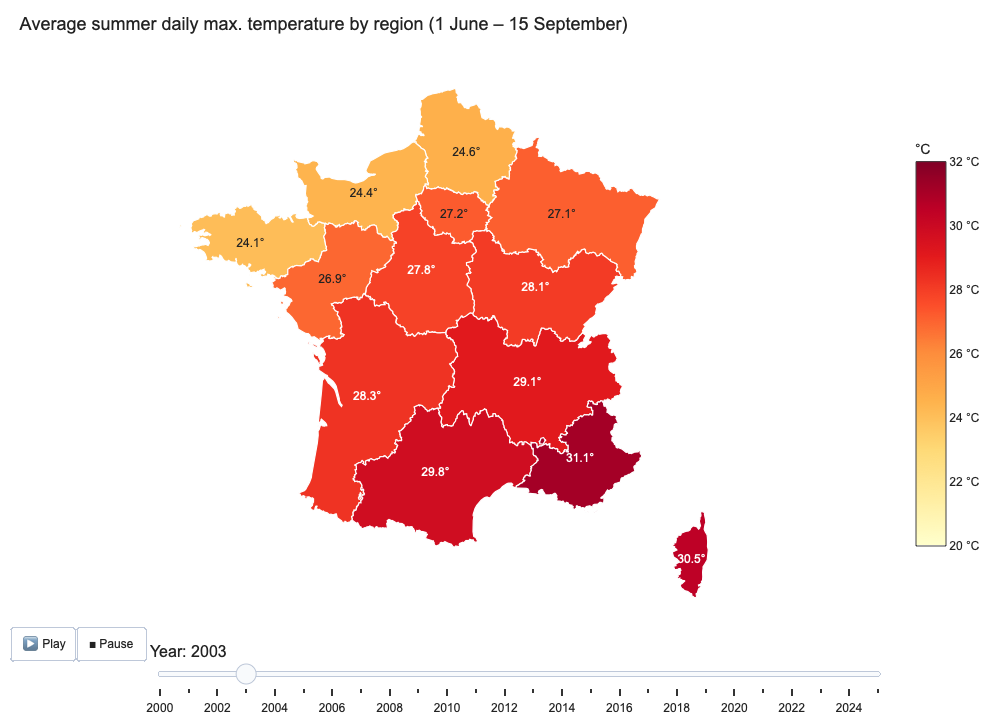

In [34]:
from pathlib import Path
from plotly.colors import sample_colorscale

VAR = "tmax"      # "tmax" = average daily max. temperature (like the other plots), "tmean" = daily mean

# --- 1. Summer value per region and year (summer_dep = summer days per département, defined above) ---
reg_year = (summer_dep.groupby(["year", "region"], as_index=False)[VAR].mean()
                      .rename(columns={VAR: "summer_temp"}))
reg_year["summer_temp"] = reg_year["summer_temp"].round(2)
# anomaly = difference to the region's own 2000–2025 average (shown when hovering)
reg_year["anomaly"] = (reg_year["summer_temp"]
                       - reg_year.groupby("region")["summer_temp"].transform("mean")).round(2)

# --- 2. Simplified region outlines (downloaded once, saved next to the notebook) ---
GEO = Path("regions_france.geojson")
if not GEO.exists():
    url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions-version-simplifiee.geojson"
    urllib.request.urlretrieve(url, GEO)
regions_simple = json.loads(GEO.read_text(encoding="utf-8"))

# --- 3. Turn each region outline into x/y coordinates for plotting ---
COS_LAT = np.cos(np.radians(46.5))          # simple projection: keeps France's proportions
def outline(geom):
    polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
    xs, ys = [], []
    for poly in polys:
        ring = poly[0]                       # outer ring
        xs += [lon * COS_LAT for lon, lat in ring] + [None]
        ys += [lat for lon, lat in ring] + [None]
    return xs, ys

shapes = {f["properties"]["nom"]: outline(f["geometry"]) for f in regions_simple["features"]}
names = sorted(shapes)
assert set(names) == set(reg_year["region"]), "region names in data and map do not match"

def label_position(xs, ys):                  # average of the outline points
    pts = [(x, y) for x, y in zip(xs, ys) if x is not None]
    return np.mean([p[0] for p in pts]), np.mean([p[1] for p in pts])
centres = {n: label_position(*shapes[n]) for n in names}
centres["Corse"] = (9.1 * COS_LAT, 42.1)

# --- 4. Colours: same scale for every year ---
CMIN = float(np.floor(reg_year["summer_temp"].min()))
CMAX = float(np.ceil(reg_year["summer_temp"].max()))
SCALE = "YlOrRd"
INK, SURFACE = "#222222", "white"            # text colour, background colour
colour = lambda v: sample_colorscale(SCALE, [(v - CMIN) / (CMAX - CMIN)])[0]
years = sorted(reg_year["year"].unique())
val = reg_year.set_index(["year", "region"])

# --- 5. All shapes and labels for one year ---
def traces_for(year):
    out = []
    for n in names:
        v, a = val.loc[(year, n), "summer_temp"], val.loc[(year, n), "anomaly"]
        xs, ys = shapes[n]
        out.append(go.Scatter(x=xs, y=ys, fill="toself", fillcolor=colour(v), mode="lines",
                              line=dict(color="white", width=1.2), hoveron="fills",
                              text=f"<b>{n}</b><br>{year}: {v:.1f} °C<br>vs 2000–25 average: {a:+.1f} °C",
                              hoverinfo="text", showlegend=False))
    out.append(go.Scatter(x=[centres[n][0] for n in names], y=[centres[n][1] for n in names],
                          mode="text", text=[f"{val.loc[(year, n), 'summer_temp']:.1f}°" for n in names],
                          textfont=dict(size=12, color=["white" if (val.loc[(year, n), "summer_temp"] - CMIN) / (CMAX - CMIN) > 0.65
                                                      else INK for n in names]),
                          hoverinfo="skip", showlegend=False))
    return out

# --- 6. Figure with year slider and play button ---
START = 2003                                  # the map opens on the 2003 heatwave
colourbar = go.Scatter(x=[None], y=[None], mode="markers", hoverinfo="skip", showlegend=False,
                       marker=dict(colorscale=SCALE, cmin=CMIN, cmax=CMAX, color=[CMIN], showscale=True,
                                   colorbar=dict(title="°C", ticksuffix=" °C", len=0.75)))
fig_map2 = go.Figure(data=traces_for(START) + [colourbar],
                     frames=[go.Frame(name=str(y), data=traces_for(y), traces=list(range(len(names) + 1)))
                             for y in years])
title = "Average summer daily max. temperature" if VAR == "tmax" else "Summer mean temperature"
fig_map2.update_layout(
    title=dict(text=f"{title} by region (1 June – 15 September)", x=0.02, font=dict(size=18)),
    xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
    height=720, margin=dict(l=10, r=10, t=60, b=10),
    paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, font=dict(family="Arial", color=INK),
    sliders=[dict(active=years.index(START), currentvalue=dict(prefix="Year: ", font=dict(size=16)),
                  pad=dict(t=10), len=0.84, x=0.16,
                  steps=[dict(label=str(y), method="animate",
                              args=[[str(y)], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                   transition=dict(duration=0))]) for y in years])],
    updatemenus=[dict(type="buttons", direction="left", x=0.0, y=0.02, xanchor="left", yanchor="top",
                      pad=dict(t=12), showactive=False,
                      buttons=[dict(label="▶️ Play", method="animate",
                                    args=[None, dict(frame=dict(duration=700, redraw=True), fromcurrent=True,
                                                     transition=dict(duration=0))]),
                               dict(label="■ Pause", method="animate",
                                    args=[[None], dict(mode="immediate", frame=dict(duration=0, redraw=False))])])],
)
fig_map2.show()

# optional: save as a stand-alone HTML file (opens in any browser, e.g. for the presentation)
# FIG = Path("figures"); FIG.mkdir(exist_ok=True)
# fig_map2.write_html(FIG / "map_summer_temp_by_region.html", include_plotlyjs=True, auto_play=False)

## Trend Mean Temperature

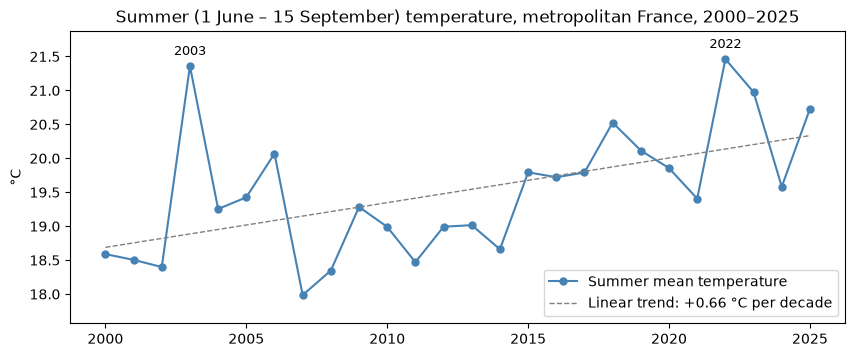

In [35]:
VAR = "tmean"   # "tmean" = daily mean temperature, "tmax" = daily max. temperature

# average summer temperature (1 June – 15 September) per year, France as a whole
st = france[france["is_summer"]].groupby("year")[VAR].mean()

# linear trend: straight line fitted through the yearly values
slope, icpt = np.polyfit(st.index, st.values, 1)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(st.index, st.values, color="steelblue", marker="o", ms=5,
        label="Summer mean temperature" if VAR == "tmean" else "Summer mean of daily max. temperature")
ax.plot(st.index, icpt + slope * st.index, color="gray", lw=1, ls="--",
        label=f"Linear trend: {slope * 10:+.2f} °C per decade")
for yr in [2003, 2022]:                                   # label the two hottest summers
    ax.annotate(str(yr), (yr, st[yr]), xytext=(0, 8), textcoords="offset points",
                ha="center", color="black", fontsize=9.5)
ax.set_title("Summer (1 June – 15 September) temperature, metropolitan France, 2000–2025")
ax.set_ylabel("°C")
ax.margins(y=0.12)                                        # some space above the highest point for the labels
ax.legend(loc="lower right")                              # legend where it doesn't cover any points
plt.show()

# optional: save the figure as PNG for the slides
# fig.savefig("figures/summer_temperature_trend.png", dpi=200, bbox_inches="tight")